# Wind Turbine Power Prediction using Linear Regression

In this project, I am using wind turbine SCADA data to explore how wind speed relates to the power generated by a turbine. I start with a basic Linear Regression model, check how well it performs, and then try a few small improvements.

The main target is `LV ActivePower (kW)`. I will compare models using MAE, RMSE and R².

**What I want to find out**
- How closely can wind speed predict active power?
- Does adding wind direction help?
- Does a squared wind-speed feature improve the results?
- Do Ridge, Lasso or ElasticNet perform better on this dataset?

This is a learning project, so I will also note where the model does not fit the data well.

## 1. Import libraries

These are the libraries I use for loading the data, making plots and building the regression models.

In [1]:
import pandas as pd                      # tables and data cleaning
import os                                # work with file paths
from collections import Counter          # count how often words appear
import warnings
warnings.filterwarnings("ignore")        # hide non-important warnings
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import kagglehub

path = kagglehub.dataset_download("berkerisen/wind-turbine-scada-dataset")

print(path)

C:\Users\riaka\.cache\kagglehub\datasets\berkerisen\wind-turbine-scada-dataset\versions\3


## 2. Download and locate the dataset

The dataset is downloaded with KaggleHub. The next cells help me find the CSV file and check what is available.

In [3]:
# Display all files in the dataset folder

for file in os.listdir(path):
    print(file)

T1.csv


In [4]:
# Load the wind turbine dataset

file_path = os.path.join(path, "T1.csv")

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

Dataset loaded successfully!
Number of rows and columns: (50530, 5)


## 3. Load the CSV file

I load `T1.csv` into a DataFrame so I can inspect the rows and columns.

In [5]:
df.head()

,Date/Time,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°)
0,01 01 2018 00:00,380.047791,5.311336,416.328908,259.994904
1,01 01 2018 00:10,453.769196,5.672167,519.917511,268.641113
2,01 01 2018 00:20,306.376587,5.216037,390.900016,272.564789
3,01 01 2018 00:30,419.645905,5.659674,516.127569,271.258087
4,01 01 2018 00:40,380.650696,5.577941,491.702972,265.674286


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50530 entries, 0 to 50529
Data columns (total 5 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Date/Time                      50530 non-null  object 
 1   LV ActivePower (kW)            50530 non-null  float64
 2   Wind Speed (m/s)               50530 non-null  float64
 3   Theoretical_Power_Curve (KWh)  50530 non-null  float64
 4   Wind Direction (°)             50530 non-null  float64
dtypes: float64(4), object(1)
memory usage: 1.9+ MB


In [7]:
print("Column names:")
print(df.columns.tolist())

Column names:
['Date/Time', 'LV ActivePower (kW)', 'Wind Speed (m/s)', 'Theoretical_Power_Curve (KWh)', 'Wind Direction (°)']


## 4. Basic data checks

I check the shape, data types, missing values and duplicate rows before starting the analysis.

In [8]:
df.shape

(50530, 5)

In [9]:
df.describe()

,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°)
count,50530.000000,50530.000000,50530.000000,50530.000000
mean,1307.684332,7.557952,1492.175463,123.687559
std,1312.459242,4.227166,1368.018238,93.443736
min,-2.471405,0.000000,0.000000,0.000000
25%,50.677890,4.201395,161.328167,49.315437
50%,825.838074,7.104594,1063.776283,73.712978
75%,2482.507568,10.300020,2964.972462,201.696720
max,3618.732910,25.206011,3600.000000,359.997589


In [10]:
df.isnull().sum()

Date/Time                        0
LV ActivePower (kW)              0
Wind Speed (m/s)                 0
Theoretical_Power_Curve (KWh)    0
Wind Direction (°)               0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.dtypes

Date/Time                         object
LV ActivePower (kW)              float64
Wind Speed (m/s)                 float64
Theoretical_Power_Curve (KWh)    float64
Wind Direction (°)               float64
dtype: object

## 5. Convert the date column

The timestamp is stored as text, so I convert it to datetime format. The format used here is day-month-year followed by hour and minute.

In [13]:
cat_cols = df.dtypes[df.dtypes=='object'].index
num_cols = df.dtypes[df.dtypes!='object'].index
print(cat_cols)
print(num_cols)

Index(['Date/Time'], dtype='object')
Index(['LV ActivePower (kW)', 'Wind Speed (m/s)',
       'Theoretical_Power_Curve (KWh)', 'Wind Direction (°)'],
      dtype='object')


In [14]:
# Convert Date/Time to datetime format
df["Date/Time"] = pd.to_datetime(
    df["Date/Time"],
    format="%d %m %Y %H:%M"
)

# Verify the data types
df.dtypes

Date/Time                        datetime64[ns]
LV ActivePower (kW)                     float64
Wind Speed (m/s)                        float64
Theoretical_Power_Curve (KWh)           float64
Wind Direction (°)                      float64
dtype: object

In [15]:
print("Start date:", df["Date/Time"].min())
print("End date:", df["Date/Time"].max())

display(df[["Date/Time"]].head())

Start date: 2018-01-01 00:00:00
End date: 2018-12-31 23:50:00


,Date/Time
0,2018-01-01 00:00:00
1,2018-01-01 00:10:00
2,2018-01-01 00:20:00
3,2018-01-01 00:30:00
4,2018-01-01 00:40:00


## 6. Explore the data

I start with the active-power distribution to see how the power readings are spread out.

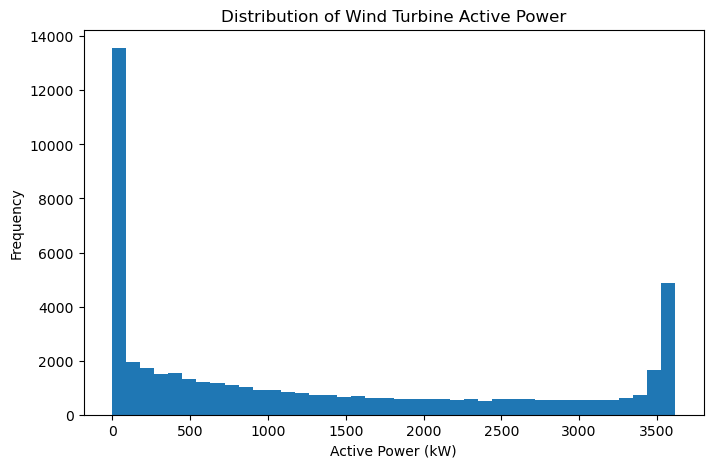

In [16]:
plt.figure(figsize=(8, 5))

plt.hist(df["LV ActivePower (kW)"], bins=40)

plt.xlabel("Active Power (kW)")
plt.ylabel("Frequency")
plt.title("Distribution of Wind Turbine Active Power")

plt.show()

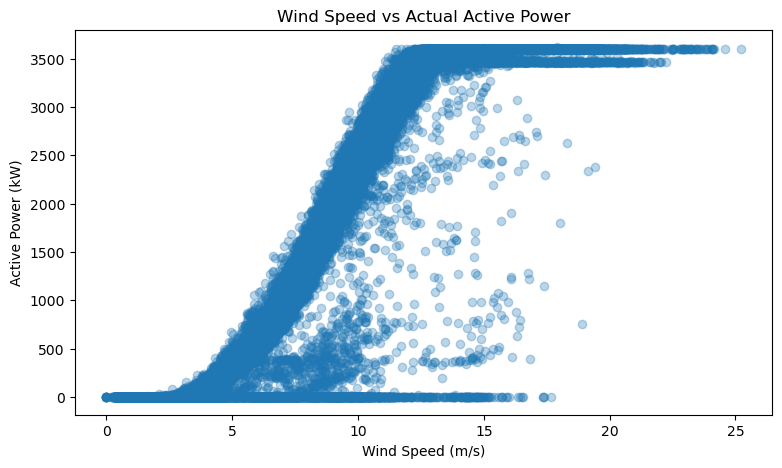

In [17]:
plt.figure(figsize=(9, 5))

plt.scatter(
    df["Wind Speed (m/s)"],
    df["LV ActivePower (kW)"],
    alpha=0.3
)

plt.xlabel("Wind Speed (m/s)")
plt.ylabel("Active Power (kW)")
plt.title("Wind Speed vs Actual Active Power")

plt.show()

### Wind speed and active power

This scatterplot helps me see whether a straight-line model is likely to fit the relationship well.

In [18]:
# Correlation between numerical variables

corr = df.select_dtypes(include="number").corr()

display(corr.round(3))

,LV ActivePower (kW),Wind Speed (m/s),Theoretical_Power_Curve (KWh),Wind Direction (°)
LV ActivePower (kW),1.000,0.913,0.950,-0.063
Wind Speed (m/s),0.913,1.000,0.944,-0.077
Theoretical_Power_Curve (KWh),0.950,0.944,1.000,-0.099
Wind Direction (°),-0.063,-0.077,-0.099,1.000


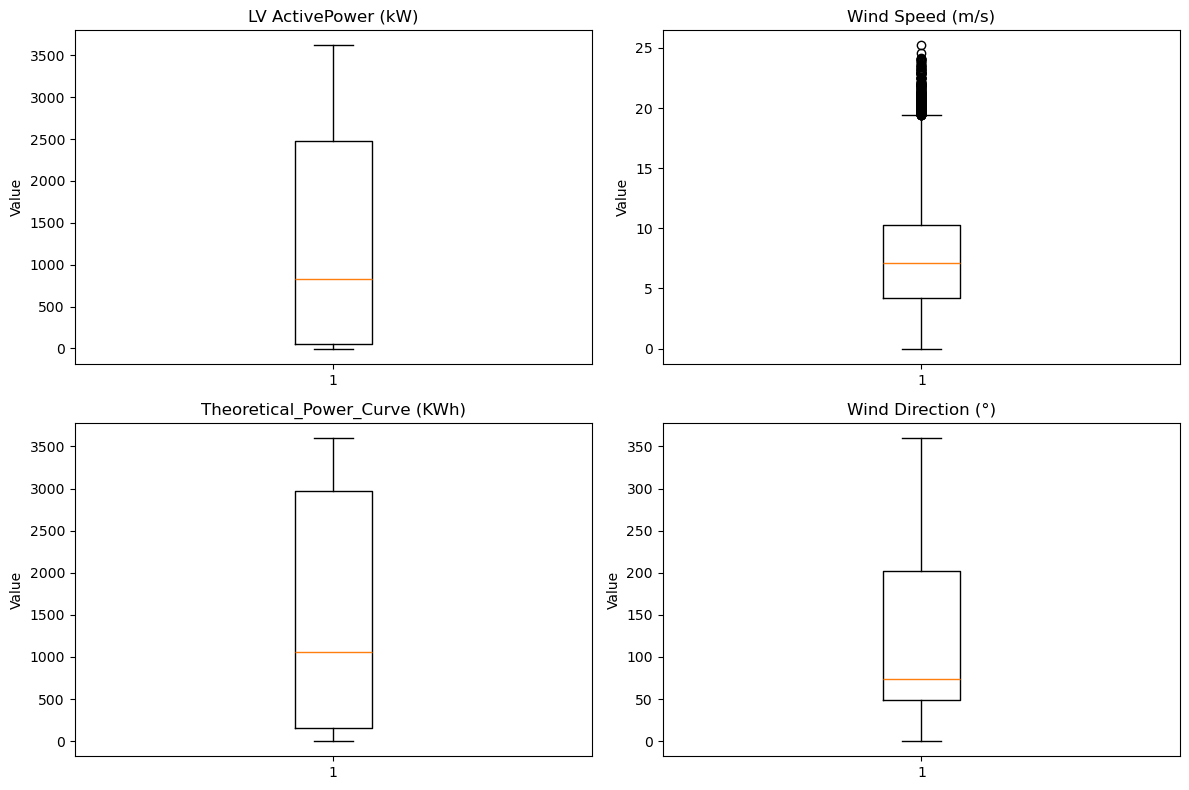

In [19]:
# Boxplots for numerical columns

num_cols = [
    "LV ActivePower (kW)",
    "Wind Speed (m/s)",
    "Theoretical_Power_Curve (KWh)",
    "Wind Direction (°)"
]

plt.figure(figsize=(12, 8))

for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 2, i)
    plt.boxplot(df[col])
    plt.title(col)
    plt.ylabel("Value")

plt.tight_layout()
plt.show()

### Correlation between numeric columns

The correlation table shows linear relationships between the numerical variables. I use it as a guide, not as proof of cause and effect.

In [20]:
# Check whether the data is in chronological order

print("Rows:", len(df))
print("Start:", df["Date/Time"].min())
print("End:", df["Date/Time"].max())

print(
    "Chronologically sorted:",
    df["Date/Time"].is_monotonic_increasing
)

Rows: 50530
Start: 2018-01-01 00:00:00
End: 2018-12-31 23:50:00
Chronologically sorted: True


In [21]:
# Check whether timestamps are unique and regularly spaced

print("Duplicate timestamps:", df["Date/Time"].duplicated().sum())

print(df["Date/Time"].diff().value_counts().head())

Duplicate timestamps: 0
Date/Time
0 days 00:10:00    50497
0 days 00:20:00       11
0 days 00:40:00        2
0 days 02:30:00        1
0 days 01:10:00        1
Name: count, dtype: int64


### Check unusual values

The boxplots flag values outside the usual IQR range. I do not remove them automatically because high wind speeds may be valid readings.

In [22]:
# Check time intervals between consecutive readings

time_gaps = df["Date/Time"].diff()

print("Most common time intervals:")
print(time_gaps.value_counts().head(10))

Most common time intervals:
Date/Time
0 days 00:10:00    50497
0 days 00:20:00       11
0 days 00:40:00        2
0 days 02:30:00        1
0 days 01:10:00        1
3 days 14:50:00        1
0 days 03:30:00        1
0 days 07:30:00        1
0 days 12:20:00        1
3 days 19:10:00        1
Name: count, dtype: int64


In [23]:
# Select input features
X = df[["Wind Speed (m/s)", "Wind Direction (°)"]]

# Select target variable
y = df["LV ActivePower (kW)"]

# Split 80% for training and 20% for testing
split = int(len(df) * 0.8)

X_train = X[:split]
X_test = X[split:]

y_train = y[:split]
y_test = y[split:]

# Check the sizes
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (40424, 2)
X_test: (10106, 2)
y_train: (40424,)
y_test: (10106,)


In [24]:
from sklearn.linear_model import LinearRegression

# Create the model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


## 7. Check timestamps

I check whether the rows are in time order and how regularly the readings are spaced. This matters when splitting time-based data.

In [25]:
# Predict power output on test data
y_pred = model.predict(X_test)

# Display first 10 actual and predicted values
print("Actual values:")
print(y_test.head(10).values)

print("\nPredicted values:")
print(y_pred[:10])

Actual values:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]

Predicted values:
[-185.23450052 -137.04511676 -145.07433544 -157.28845299 -256.20951629
 -199.18830747  -94.87600721 -105.52059502 -228.52861735 -515.69047951]


In [26]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 413.0752240196789
MSE: 305495.10315772553
RMSE: 552.7161144364487
R2 Score: 0.8303828487847968


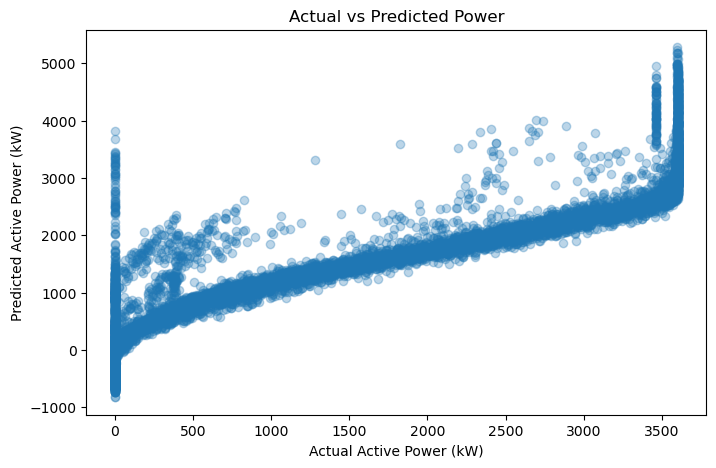

In [27]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.3)

plt.xlabel("Actual Active Power (kW)")
plt.ylabel("Predicted Active Power (kW)")
plt.title("Actual vs Predicted Power")

plt.show()

In [28]:
# Display model coefficients

print("Intercept:", model.intercept_)

print("Wind Speed Coefficient:", model.coef_[0])

print("Wind Direction Coefficient:", model.coef_[1])

Intercept: -827.5705223720204
Wind Speed Coefficient: 282.75054579534066
Wind Direction Coefficient: -0.021304445345509793


## 8. Build the baseline model

I use the earlier 80% of the rows for training and the latest 20% for testing. This keeps the test period later in time than the training period.

In [29]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

# Model 1: Wind speed only
X_train_speed = X_train[["Wind Speed (m/s)"]]
X_test_speed = X_test[["Wind Speed (m/s)"]]

model_speed = LinearRegression()
model_speed.fit(X_train_speed, y_train)

pred_speed = model_speed.predict(X_test_speed)

print("Wind Speed Only")
print("MAE:", mean_absolute_error(y_test, pred_speed))
print("R2 Score:", r2_score(y_test, pred_speed))


# Model 2: Wind speed and wind direction
pred_both = model.predict(X_test)

print("\nWind Speed + Wind Direction")
print("MAE:", mean_absolute_error(y_test, pred_both))
print("R2 Score:", r2_score(y_test, pred_both))

Wind Speed Only
MAE: 412.899969847344
R2 Score: 0.8305159475353061

Wind Speed + Wind Direction
MAE: 413.0752240196789
R2 Score: 0.8303828487847968


In [30]:
# # Calculate residuals
# residuals = y_test - pred_speed

# # Plot residuals
# plt.figure(figsize=(8, 5))

# plt.scatter(pred_speed, residuals, alpha=0.3)
# plt.axhline(y=0, color="red")

# plt.xlabel("Predicted Power (kW)")
# plt.ylabel("Residuals (kW)")
# plt.title("Residual Plot - Linear Regression")

# plt.show()

### Make predictions and evaluate

I compare predictions with the held-out test values using MAE, RMSE and R². For regression, R² is not the same as classification accuracy.

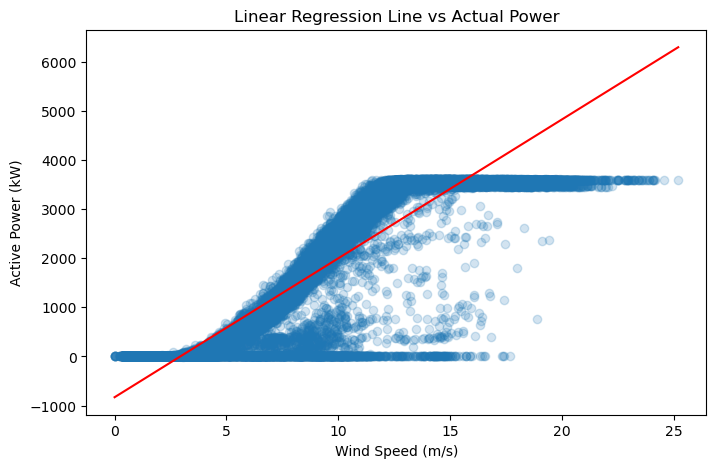

In [31]:
# Sort wind speed before plotting the regression line
wind_speed_sorted = df[["Wind Speed (m/s)"]].sort_values(
    "Wind Speed (m/s)"
)

power_pred_line = model_speed.predict(wind_speed_sorted)

plt.figure(figsize=(8, 5))

plt.scatter(
    df["Wind Speed (m/s)"],
    df["LV ActivePower (kW)"],
    alpha=0.2
)

plt.plot(
    wind_speed_sorted["Wind Speed (m/s)"],
    power_pred_line,
    color="red"
)

plt.xlabel("Wind Speed (m/s)")
plt.ylabel("Active Power (kW)")
plt.title("Linear Regression Line vs Actual Power")

plt.show()

In [32]:
# Create a squared wind speed feature

df["Wind Speed Squared"] = df["Wind Speed (m/s)"] ** 2

# Check the new column
display(df[["Wind Speed (m/s)", "Wind Speed Squared"]].head())


,Wind Speed (m/s),Wind Speed Squared
0,5.311336,28.210291
1,5.672167,32.173476
2,5.216037,27.207040
3,5.659674,32.031912
4,5.577941,31.113425


In [33]:
# Select features and target
X_new = df[["Wind Speed (m/s)", "Wind Speed Squared"]]
y = df["LV ActivePower (kW)"]

# Split data into training and testing sets
split = int(len(df) * 0.8)

X_train_new = X_new[:split]
X_test_new = X_new[split:]

y_train_new = y[:split]
y_test_new = y[split:]

print("Training data:", X_train_new.shape)
print("Testing data:", X_test_new.shape)

Training data: (40424, 2)
Testing data: (10106, 2)


### Look at actual vs predicted power

Ideally, predictions should be close to the actual values. A wide spread means the model is making larger errors for some observations.

In [34]:
# Create and train the new model
model_new = LinearRegression()

model_new.fit(X_train_new, y_train_new)

print("Improved model trained successfully!")

Improved model trained successfully!


In [35]:
# Make predictions
y_pred_new = model_new.predict(X_test_new)

# Evaluate the model
mae_new = mean_absolute_error(y_test_new, y_pred_new)
mse_new = mean_squared_error(y_test_new, y_pred_new)
rmse_new = np.sqrt(mse_new)
r2_new = r2_score(y_test_new, y_pred_new)

print("New MAE:", mae_new)
print("New MSE:", mse_new)
print("New RMSE:", rmse_new)
print("New R2 Score:", r2_new)

New MAE: 414.716700362376
New MSE: 301652.18396257807
New RMSE: 549.2287173505935
New R2 Score: 0.83251651639352


In [36]:
print("Intercept:", model_new.intercept_)

print("Wind Speed Coefficient:", model_new.coef_[0])

print("Wind Speed Squared Coefficient:", model_new.coef_[1])

Intercept: -979.9336048456923
Wind Speed Coefficient: 328.25657503037246
Wind Speed Squared Coefficient: -2.5841876389230474


### Check whether wind direction helps

I compare a model using wind speed alone with one using wind speed and wind direction.

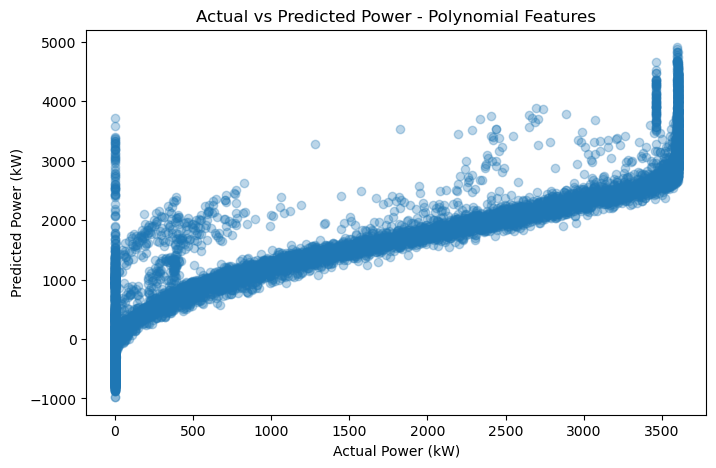

In [37]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test_new, y_pred_new, alpha=0.3)

plt.xlabel("Actual Power (kW)")
plt.ylabel("Predicted Power (kW)")
plt.title("Actual vs Predicted Power - Polynomial Features")

plt.show()

In [51]:

# Compare baseline and polynomial models

# Calculate metrics for the wind-speed-only model
mae_speed = mean_absolute_error(y_test, pred_speed)
rmse_speed = np.sqrt(mean_squared_error(y_test, pred_speed))
r2_speed = r2_score(y_test, pred_speed)

# Create a comparison table using the calculated metrics
comparison = pd.DataFrame({
    "Model": [
        "Wind Speed Only",
        "Wind Speed + Squared"
    ],
    "MAE": [
        mae_speed,
        mae_new
    ],
    "RMSE": [
        rmse_speed,
        rmse_new
    ],
    "R2 Score": [
        r2_speed,
        r2_new
    ]
})

display(comparison.round(4))


,Model,MAE,RMSE,R2 Score
0,Wind Speed Only,412.9000,552.4992,0.8305
1,Wind Speed + Squared,414.7167,549.2287,0.8325


In [39]:
from sklearn.linear_model import Ridge

# Create Ridge model
ridge_model = Ridge(alpha=1.0)

# Train the model
ridge_model.fit(X_train_new, y_train_new)

print("Ridge model trained successfully!")

Ridge model trained successfully!


### Check residuals

Residuals are calculated as actual power minus predicted power. A pattern in the residuals can show where the straight-line model is missing something.

In [40]:
# Make predictions
ridge_pred = ridge_model.predict(X_test_new)

# Calculate evaluation metrics
ridge_mae = mean_absolute_error(y_test_new, ridge_pred)
ridge_mse = mean_squared_error(y_test_new, ridge_pred)
ridge_rmse = np.sqrt(ridge_mse)
ridge_r2 = r2_score(y_test_new, ridge_pred)

print("Ridge MAE:", ridge_mae)
print("Ridge RMSE:", ridge_rmse)
print("Ridge R2 Score:", ridge_r2)

Ridge MAE: 414.7165660213702
Ridge RMSE: 549.2287925075741
Ridge R2 Score: 0.832516470556318


In [41]:
from sklearn.linear_model import Lasso

# Create Lasso model
lasso_model = Lasso(alpha=1.0)

# Train the model
lasso_model.fit(X_train_new, y_train_new)

print("Lasso model trained successfully!")

Lasso model trained successfully!


In [42]:
# Make predictions
lasso_pred = lasso_model.predict(X_test_new)

# Calculate evaluation metrics
lasso_mae = mean_absolute_error(y_test_new, lasso_pred)
lasso_mse = mean_squared_error(y_test_new, lasso_pred)
lasso_rmse = np.sqrt(lasso_mse)
lasso_r2 = r2_score(y_test_new, lasso_pred)

print("Lasso MAE:", lasso_mae)
print("Lasso RMSE:", lasso_rmse)
print("Lasso R2 Score:", lasso_r2)

Lasso MAE: 414.69746572799477
Lasso RMSE: 549.2389284902151
Lasso R2 Score: 0.8325102887033821


## 9. Try a squared wind-speed feature

The power curve looks nonlinear, so I add wind speed squared as a simple feature-engineering experiment.

In [43]:
from sklearn.linear_model import ElasticNet

# Create ElasticNet model
elastic_model = ElasticNet(alpha=1.0, l1_ratio=0.5)

# Train the model
elastic_model.fit(X_train_new, y_train_new)

print("ElasticNet model trained successfully!")

ElasticNet model trained successfully!


In [44]:
# Make predictions
elastic_pred = elastic_model.predict(X_test_new)

# Calculate evaluation metrics
elastic_mae = mean_absolute_error(y_test_new, elastic_pred)
elastic_mse = mean_squared_error(y_test_new, elastic_pred)
elastic_rmse = np.sqrt(elastic_mse)
elastic_r2 = r2_score(y_test_new, elastic_pred)

print("ElasticNet MAE:", elastic_mae)
print("ElasticNet RMSE:", elastic_rmse)
print("ElasticNet R2 Score:", elastic_r2)

ElasticNet MAE: 417.11775351171366
ElasticNet RMSE: 558.6824806314745
ElasticNet R2 Score: 0.8267011753798014


In [45]:
# Compare the models using the scores calculated above

comparison = pd.DataFrame({
    "Model": [
        "Linear Regression - Wind Speed",
        "Polynomial Linear Regression",
        "Ridge Regression",
        "Lasso Regression",
        "ElasticNet"
    ],
    "MAE": [
        mean_absolute_error(y_test, pred_speed),
        mae_new,
        ridge_mae,
        lasso_mae,
        elastic_mae
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, pred_speed)),
        rmse_new,
        ridge_rmse,
        lasso_rmse,
        elastic_rmse
    ],
    "R2 Score": [
        r2_score(y_test, pred_speed),
        r2_new,
        ridge_r2,
        lasso_r2,
        elastic_r2
    ]
})

display(comparison.round(4))

,Model,MAE,RMSE,R2 Score
0,Linear Regression - Wind Speed,412.9000,552.4992,0.8305
1,Polynomial Linear Regression,414.7167,549.2287,0.8325
2,Ridge Regression,414.7166,549.2288,0.8325
3,Lasso Regression,414.6975,549.2389,0.8325
4,ElasticNet,417.1178,558.6825,0.8267


### Train and evaluate the new model

I keep the same chronological split so the baseline and the squared-feature model can be compared on the same test observations.

In [46]:
# Check correlation between polynomial features

display(
    X_train_new.corr().round(3)
)

,Wind Speed (m/s),Wind Speed Squared
Wind Speed (m/s),1.000,0.954
Wind Speed Squared,0.954,1.000


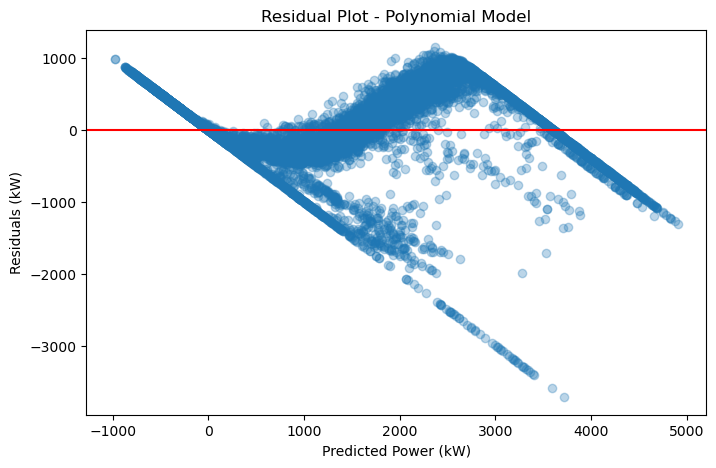

In [47]:
# Calculate residuals for the polynomial model
residuals_new = y_test_new - y_pred_new

# Plot residuals
plt.figure(figsize=(8, 5))

plt.scatter(y_pred_new, residuals_new, alpha=0.3)
plt.axhline(y=0, color="red")

plt.xlabel("Predicted Power (kW)")
plt.ylabel("Residuals (kW)")
plt.title("Residual Plot - Polynomial Model")

plt.show()

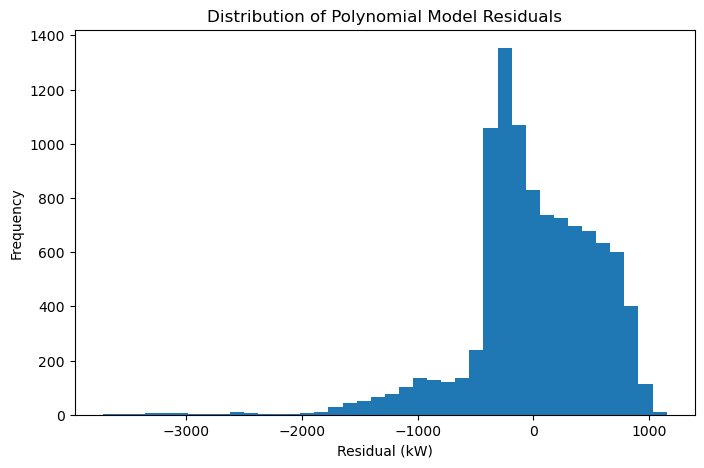

In [48]:
# Calculate residuals for the polynomial-feature model
residuals_new = y_test_new - y_pred_new

# Plot a histogram of residuals
plt.figure(figsize=(8, 5))
plt.hist(residuals_new, bins=40)
plt.xlabel("Residual (kW)")
plt.ylabel("Frequency")
plt.title("Distribution of Polynomial Model Residuals")
plt.show()


In [49]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# Divide the training data into 5 time-ordered folds
time_split = TimeSeriesSplit(n_splits=5)
fold_mae = []

# Train and test the model on each fold
for train_index, valid_index in time_split.split(X_train_new):
    X_fold_train = X_train_new.iloc[train_index]
    X_fold_valid = X_train_new.iloc[valid_index]

    y_fold_train = y_train_new.iloc[train_index]
    y_fold_valid = y_train_new.iloc[valid_index]

    # Train the model
    fold_model = LinearRegression()
    fold_model.fit(X_fold_train, y_fold_train)

    # Predict and calculate the error
    fold_predictions = fold_model.predict(X_fold_valid)
    fold_score = mean_absolute_error(y_fold_valid, fold_predictions)

    fold_mae.append(fold_score)
    print("Fold MAE:", round(fold_score, 2))

# Show the average error across the folds
print("Average MAE:", round(np.mean(fold_mae), 2))

Fold MAE: 466.86
Fold MAE: 326.94
Fold MAE: 306.65
Fold MAE: 365.58
Fold MAE: 360.84
Average MAE: 365.37


### Compare the models

MAE, RMSE and R² can tell slightly different stories, so I look at all three rather than relying on just one score.

In [50]:
# Display all model results
display(comparison.round(4))

# Find the model with the lowest MAE
best_mae = comparison["MAE"].min()
print("Lowest MAE:", best_mae)

# Find the model with the lowest RMSE
best_rmse = comparison["RMSE"].min()
print("Lowest RMSE:", best_rmse)

,Model,MAE,RMSE,R2 Score
0,Linear Regression - Wind Speed,412.9000,552.4992,0.8305
1,Polynomial Linear Regression,414.7167,549.2287,0.8325
2,Ridge Regression,414.7166,549.2288,0.8325
3,Lasso Regression,414.6975,549.2389,0.8325
4,ElasticNet,417.1178,558.6825,0.8267


Lowest MAE: 412.899969847344
Lowest RMSE: 549.2287173505935


### Project conclusion
This project used 50,530 SCADA observations from 2018. The data was checked for missing values, duplicate rows and timestamp order. The first 80% of observations were used for training, and the final 20% were reserved for testing.

The baseline Linear Regression using wind speed alone achieved approximately:
- MAE: 412.90 kW
- RMSE: 552.72 kW
- R²: 0.8305
The squared wind-speed experiment achieved approximately:
- MAE: 414.72 kW
- RMSE: 549.23 kW
- R²: 0.8325
The squared feature slightly improved RMSE and R² but worsened MAE. Ridge and Lasso produced nearly identical results in the initial unscaled experiments, while ElasticNet performed worse with the chosen settings.

Final takeaway: The models explain a substantial portion of test-set variation, but visible residual patterns and the nonlinear turbine power curve show that the model is not fully adequate. Results should be reported with these limitations rather than describing R² as “accuracy.”

## 10. Regularized regression

I also try Ridge, Lasso and ElasticNet. These methods add penalties to the model coefficients. The results below are initial experiments using the same feature set.